In [10]:
import deap
import numpy as np
from deap import algorithms, base, creator, tools
SEED = 42
import random
import csv
import random
from pathlib import Path

import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

### Does cooperation emerge and remain stable in an evolving population, and how does the answer depend on the noise level?

In [5]:
NOISE_LEVELS = [0, 0.01, 0.05]
# all combinations of 5 bits
STRATEGIES = [tuple([int(l) for l in format(i, '05b')]) for i in range(32)]
rng = np.random.default_rng(SEED)

In [95]:
# name the classic strategies
STRATEGY_NAMES = {

(0, 0, 0, 0, 0): "ALLC", # always cooperate

(1, 1, 1, 1, 1): "ALLD", # always defect

(0, 0, 1, 0, 1): "TFT", # tit for tat, start cooperatively

(0, 0, 1, 1, 0): "PAVLOV", # win-stay lose-shift, start C

(0, 0, 1, 1, 1): "GRIM", # start cooperative, take any betrayal to heart and never forgive

(1, 0, 1, 0, 1): "STFT", # suspicious tit for tat

(0, 0, 0, 0, 1): "CAP", # nice but capricious: will double down on mutual betrayal

(0, 0, 0, 1, 0): "VICE", # nice person but corrupted by successful betrayal

(0, 0, 0, 1, 1): "ADDICT", # nice person but gets addicted to cooperation/defection

(0, 0, 1, 0, 0): "RIGHTEOUS", # good person but shows short-term righteous anger when duped

(0, 1, 0, 0, 0): "PEST", # provocateur; cooperative until mutual cooperation achieved

(0, 1, 0, 0, 1): "LSWS", # lose stay win shift - never let them know your next move

(0, 1, 0, 1, 0): "CONTR", # contrarian opposes opponent's last move - starts C

(0, 1, 0, 1, 1): "BULLY", # defects always except when punished, and starts nice

(0, 1, 1, 0, 0): "ALT", # alternates move each time, starting with C

(0, 1, 1, 0, 1): "GUILT", # always defects but feels remorse after successful dupe. starts C

(0, 1, 1, 1, 0): "GASLGHT", # always defects but chooses moral highroad when both do it. starts C

(0, 1, 1, 1, 1): "TEMU", # looks nice at a glance, but turns out to be consistently defective

(1, 0, 0, 0, 0): "HARMLESS", # starts mean but turns out to be fully cooperative

(1, 0, 0, 0, 1): "SCAP", # suspicious and doubles down on mutual betrayal

(1, 0, 0, 1, 0): "SVICE", # starts by defecting, gets hooked if successfully betrays, otherwise repents

(1, 0, 0, 1, 1): "SADDICT", # starts by defecting; addicted to cooperation or defection

(1, 0, 1, 0, 0): "HYPOCRITE", # short-term righteous anger on being duped, but starts with defection

(1, 0, 1, 1, 0): "SPAVLOV", # suspicious pavlov

(1, 0, 1, 1, 1): "SGRIM", # suspicious grim

(1, 1, 0, 0, 0): "SPEST", # suspicious provocateur

(1, 1, 0, 0, 1): "SLSWS", # suspicious lose-stay win-shift

(1, 1, 0, 1, 0): "SCONTR", # suspicious contrarian

(1, 1, 0, 1, 1): "SBULLY", # defects always except when punished

(1, 1, 1, 0, 0): "SALT", # suspicious alternator

(1, 1, 1, 0, 1): "SGUILT", # starts by defecting, only shows remorse for successful dupe

(1, 1, 1, 1, 0): "SGASLGHT", # starts by defecting and keeps doing it until both do it

}

In [8]:
P1_HEAD_TO_HEAD = np.array([[3, 0], [5, 1]]) # outcomes for p1 in prisoners dilemma

#### Compute expected payoff matrix

In [9]:
# Payoff conditional on the previous outcome; player 2 uses their own perspective.
n = len(STRATEGIES)
PAYOFFS = np.zeros((n, n, 4))
for i in range(n):
    for j in range(n):
        for outcome in range(4):
            p1_action = STRATEGIES[i][outcome + 1]
            p2_outcome = [0, 2, 1, 3][outcome] # player two perspective has CD and DC flipped
            p2_action = STRATEGIES[j][p2_outcome + 1]
            PAYOFFS[i, j, outcome] = P1_HEAD_TO_HEAD[p1_action, p2_action]


In [89]:
def bits_to_id(bits):
    return int("".join(str(i) for i in bits), 2)

BITS_TO_IDS = { strat : bits_to_id(strat) for strat in STRATEGIES}

In [24]:
BITS_TO_IDS

{(0, 0, 0, 0, 0): 0,
 (0, 0, 0, 0, 1): 1,
 (0, 0, 0, 1, 0): 2,
 (0, 0, 0, 1, 1): 3,
 (0, 0, 1, 0, 0): 4,
 (0, 0, 1, 0, 1): 5,
 (0, 0, 1, 1, 0): 6,
 (0, 0, 1, 1, 1): 7,
 (0, 1, 0, 0, 0): 8,
 (0, 1, 0, 0, 1): 9,
 (0, 1, 0, 1, 0): 10,
 (0, 1, 0, 1, 1): 11,
 (0, 1, 1, 0, 0): 12,
 (0, 1, 1, 0, 1): 13,
 (0, 1, 1, 1, 0): 14,
 (0, 1, 1, 1, 1): 15,
 (1, 0, 0, 0, 0): 16,
 (1, 0, 0, 0, 1): 17,
 (1, 0, 0, 1, 0): 18,
 (1, 0, 0, 1, 1): 19,
 (1, 0, 1, 0, 0): 20,
 (1, 0, 1, 0, 1): 21,
 (1, 0, 1, 1, 0): 22,
 (1, 0, 1, 1, 1): 23,
 (1, 1, 0, 0, 0): 24,
 (1, 1, 0, 0, 1): 25,
 (1, 1, 0, 1, 0): 26,
 (1, 1, 0, 1, 1): 27,
 (1, 1, 1, 0, 0): 28,
 (1, 1, 1, 0, 1): 29,
 (1, 1, 1, 1, 0): 30,
 (1, 1, 1, 1, 1): 31}

### Define evaluation function
Do round robin against all other individuals in population

In [25]:
P2_OUTCOME_MAP = [0, 2, 1, 3] # CD <=> DC from p2 perspective
# first need game function to incorporate noise
def game(last_outcome, p1, p2, noise, rng, h2h, return_cooperation=False):
    if last_outcome is None: # go with first move for strat
        p1_intended = p1[0]
        p2_intended = p2[0]
    else:
        p1_intended = p1[last_outcome + 1]
        p2_intended = p2[P2_OUTCOME_MAP[last_outcome] + 1]
    # players make moves based on last outcome but with p(error) = noise
    if noise == 0:
        p1_move, p2_move = p1_intended, p2_intended
    else:
        p1_move = p1_intended if rng.random() > noise else 1 - p1_intended
        p2_move = p2_intended if rng.random() > noise else 1 - p2_intended
    new_outcome = 2 * p1_move + p2_move # CC = 0, CD = 1, DC = 2, DD = 3
    if return_cooperation:
        return h2h[p1_move, p2_move], new_outcome, int(p1_intended == 0), int(p1_move == 0)
    return h2h[p1_move, p2_move], new_outcome    

In [26]:
N_ROUNDS = 150
N_MATCH_REPLICATES = 20  # independent noisy matches per strategy pair
# DEAP calls evaluate(ind) only, so opponents/noise live here.
# Each generation, set current_pop[:] = pop before evaluating.
current_pop = []
current_noise = 0.0

def play_match(p1, p2, noise, rng, h2h, n_rounds=N_ROUNDS, return_cooperation=False):
    last_outcome = None
    total = 0.0
    intended_total = realized_total = 0
    for _ in range(n_rounds):
        payoff, last_outcome, intended, realized = game(
            last_outcome, p1, p2, noise, rng, h2h, return_cooperation=True
        )
        total += payoff
        intended_total += intended
        realized_total += realized
    if return_cooperation:
        return total / n_rounds, intended_total / n_rounds, realized_total / n_rounds
    return total / n_rounds

In [27]:
# Estimate each ordered matchup's expected payoff with independent trajectories.
PAYOFF_SEED = SEED + 100_000
NOISE_PAYOFFS = {noise: np.zeros((len(STRATEGIES), len(STRATEGIES))) for noise in NOISE_LEVELS}
NOISE_INTENDED_COOPERATION = {noise: np.zeros_like(NOISE_PAYOFFS[noise]) for noise in NOISE_LEVELS}
NOISE_REALIZED_COOPERATION = {noise: np.zeros_like(NOISE_PAYOFFS[noise]) for noise in NOISE_LEVELS}

for noise_idx, noise in enumerate(NOISE_LEVELS):
    payoff_rng = np.random.default_rng(PAYOFF_SEED + noise_idx)
    for i, strategy_i in enumerate(STRATEGIES):
        for j, strategy_j in enumerate(STRATEGIES):
            samples = [
                play_match(strategy_i, strategy_j, noise, payoff_rng, P1_HEAD_TO_HEAD,
                           return_cooperation=True)
                for _ in range(1 if noise == 0 else N_MATCH_REPLICATES)
            ]
            # Repeating a deterministic payoff preserves the original mean's rounding.
            if noise == 0:
                samples *= N_MATCH_REPLICATES
            payoffs, intended, realized = zip(*samples)
            NOISE_PAYOFFS[noise][i, j] = np.mean(payoffs)
            NOISE_INTENDED_COOPERATION[noise][i, j] = np.mean(intended)
            NOISE_REALIZED_COOPERATION[noise][i, j] = np.mean(realized)

for noise in NOISE_LEVELS:
    for matrix in (NOISE_INTENDED_COOPERATION[noise], NOISE_REALIZED_COOPERATION[noise]):
        assert np.all((0 <= matrix) & (matrix <= 1))
    if noise == 0:
        assert np.array_equal(NOISE_INTENDED_COOPERATION[noise], NOISE_REALIZED_COOPERATION[noise])


def round_robin_evaluate(ind, population=None, noise=None):
    # this functions plays an individual against all other competitors in its generation to measure its fitness

    # use current population and current noise global vars to get around tb.evaluate()'s single arg
    if population is None:
        population = current_pop
    if noise is None:
        noise = current_noise
    competitors = [competitor for competitor in population if competitor is not ind] # exclude ind from people to play against
    if not competitors:
        return (0.0,)
    ind_index = BITS_TO_IDS[tuple(ind)]
    scores = [NOISE_PAYOFFS[noise][ind_index, BITS_TO_IDS[tuple(c)]] for c in competitors]
    return (float(np.mean(scores)),)

In [86]:
# Define constants for running the experiments using suggested defaults
N_RUNS = 50
POP_SIZE = 100
N_GENERATIONS = 500
CXPB = 0.7
MUTPB = 1.0 # keep this 1 as indpb controls bit flipping mutations
MUTATION_INDPB = 0.01
TOURNAMENT_SIZE = 3
ELITE_SIZE = 2
ROLLING_WINDOW = 11  # used for plots only; raw generation values are saved
OUTPUT_DIR = Path("evolution_results")

# Keep the same seed schedule at each noise level for paired comparisons.
RUN_SEEDS = [SEED + run_idx for run_idx in range(N_RUNS)]

In [ ]:
try:
    del creator.FitnessMax
    del creator.Individual
except Exception:
    pass

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

tb = base.Toolbox()
tb.register("bit", random.randint, 0, 1)
tb.register("individual", tools.initRepeat, creator.Individual, tb.bit, n=5)
tb.register("population", tools.initRepeat, list, tb.individual)
tb.register("evaluate", round_robin_evaluate)
tb.register("mate", tools.cxUniform, indpb=0.5)
tb.register("mutate", tools.mutFlipBit, indpb=MUTATION_INDPB)
tb.register("select", tools.selTournament, tournsize=TOURNAMENT_SIZE)

def strategy_frequencies(pop):
    ids = [BITS_TO_IDS[tuple(ind)] for ind in pop]
    return np.bincount(ids, minlength=len(STRATEGIES)) / len(pop)


def run_evolution(noise, seed):
    global current_noise
    current_noise = noise
    random.seed(seed)
    pop = tb.population(n=POP_SIZE)
    current_pop[:] = pop
    for ind in pop:
        ind.fitness.values = tb.evaluate(ind)

    mean_payoff = [float(np.mean([ind.fitness.values[0] for ind in pop]))]
    best_payoff = [float(max(ind.fitness.values[0] for ind in pop))]
    hist_freq = [strategy_frequencies(pop)]

    # Run the full horizon so generation-by-generation records are comparable.
    # Elites preserve genotypes; their fitness is recalculated in each new population.
    for _ in range(N_GENERATIONS):
        elites = tools.selBest(pop, ELITE_SIZE)
        offspring = algorithms.varAnd(
            tb.select(pop, len(pop)), tb, cxpb=CXPB, mutpb=MUTPB
        )
        for i, elite in enumerate(elites):
            offspring[i] = tb.clone(elite) # not really necessary

        # Invalidate all offspring's fitness value so it can be recalculated against the current generation
        for ind in offspring:
            if ind.fitness.valid:
                del ind.fitness.values #why do we do this if we dont check it?
        current_pop[:] = offspring
        for ind in offspring:
            ind.fitness.values = tb.evaluate(ind)
        pop = offspring

        generation_scores = np.array([ind.fitness.values[0] for ind in pop])
        mean_payoff.append(float(generation_scores.mean()))
        best_payoff.append(float(generation_scores.max()))
        hist_freq.append(strategy_frequencies(pop))

    # Ordered pairs exclude an individual playing itself, but include distinct
    # individuals with the same strategy. Rows are generations, columns strategies.
    frequencies = np.array(hist_freq)
    population_size = len(pop)
    def population_cooperation(matrix):
        if population_size < 2:
            return np.zeros(len(frequencies))
        pair_totals = np.einsum("gi,ij,gj->g", frequencies, matrix, frequencies)
        self_totals = frequencies @ np.diag(matrix) / population_size
        return (pair_totals - self_totals) * population_size / (population_size - 1)

    final_leader = int(np.argmax(hist_freq[-1]))
    return {
        "noise": noise,
        "seed": seed,
        "mean_payoff": np.array(mean_payoff),
        "best_payoff": np.array(best_payoff),
        "freq": frequencies,
        "intended_cooperation": population_cooperation(NOISE_INTENDED_COOPERATION[noise]),
        "realized_cooperation": population_cooperation(NOISE_REALIZED_COOPERATION[noise]),
        "final_leader": STRATEGIES[final_leader],
        "final_leader_frequency": float(hist_freq[-1][final_leader]),
    }


results = {
    noise: [run_evolution(noise, seed) for seed in RUN_SEEDS]
    for noise in NOISE_LEVELS
}

In [ ]:
# Save one row per run and generation, including strategy frequencies and all run parameters.
OUTPUT_DIR.mkdir(exist_ok=True)
strategy_columns = ["freq_" + "".join(map(str, strategy)) for strategy in STRATEGIES]
generation_rows = []
run_rows = []
for noise, runs in results.items():
    for run_idx, run in enumerate(runs):
        run_rows.append({
            "noise": noise,
            "run": run_idx + 1,
            "evolution_seed": run["seed"],
            "final_leader": "".join(map(str, run["final_leader"])),
            "final_leader_frequency": run["final_leader_frequency"],
        })
        for generation in range(N_GENERATIONS + 1):
            row = {
                "noise": noise,
                "run": run_idx + 1,
                "evolution_seed": run["seed"],
                "generation": generation,
                "mean_payoff": run["mean_payoff"][generation],
                "best_payoff": run["best_payoff"][generation],
                "intended_cooperation": run["intended_cooperation"][generation],
                "realized_cooperation": run["realized_cooperation"][generation],
            }
            row.update(dict(zip(strategy_columns, run["freq"][generation])))
            generation_rows.append(row)

with (OUTPUT_DIR / "generation_data.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=generation_rows[0].keys())
    writer.writeheader()
    writer.writerows(generation_rows)
with (OUTPUT_DIR / "run_metadata.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=run_rows[0].keys())
    writer.writeheader()
    writer.writerows(run_rows)
print(f"Saved {len(generation_rows)} generation records and {len(run_rows)} run records to {OUTPUT_DIR}/")

In [87]:
# Reconstruct the in-memory results structure from the saved CSV files.
OUTPUT_DIR = Path("evolution_results")
with (OUTPUT_DIR / "generation_data.csv").open("r", newline="") as f:
    generation_data = list(csv.DictReader(f))

with (OUTPUT_DIR / "run_metadata.csv").open("r", newline="") as f:
    run_metadata = list(csv.DictReader(f))

# CSV values are strings, so normalize keys before grouping and joining.
metadata_by_key = {(float(row["noise"]), int(row["run"])): row for row in run_metadata}
generation_rows_by_key = {}
for row in generation_data:
    key = (float(row["noise"]), int(row["run"]))
    generation_rows_by_key.setdefault(key, []).append(row)

results = {}
for noise in NOISE_LEVELS:
    runs = []
    run_numbers = sorted(run for row_noise, run in generation_rows_by_key if row_noise == noise)
    for run_number in run_numbers:
        key = (noise, run_number)
        rows = sorted(generation_rows_by_key[key], key=lambda row: int(row["generation"]))
        metadata = metadata_by_key[key]
        run = {
            "noise": noise,
            "run": run_number,
            "seed": int(metadata["evolution_seed"]),
            "mean_payoff": np.array([float(row["mean_payoff"]) for row in rows]),
            "best_payoff": np.array([float(row["best_payoff"]) for row in rows]),
            "intended_cooperation": np.array([float(row["intended_cooperation"]) for row in rows]),
            "realized_cooperation": np.array([float(row["realized_cooperation"]) for row in rows]),
            "freq": np.array([
                [float(row["freq_" + "".join(map(str, strategy))]) for strategy in STRATEGIES]
                for row in rows
            ]),
            "final_leader": tuple(int(bit) for bit in metadata["final_leader"]),
            "final_leader_frequency": float(metadata["final_leader_frequency"]),
        }
        runs.append(run)
    results[noise] = runs


# Explain why the result is what it is, and support the explanation with a measurement (a
# diversity curve, a count of feasible individuals, a heritability coefficient. . . 

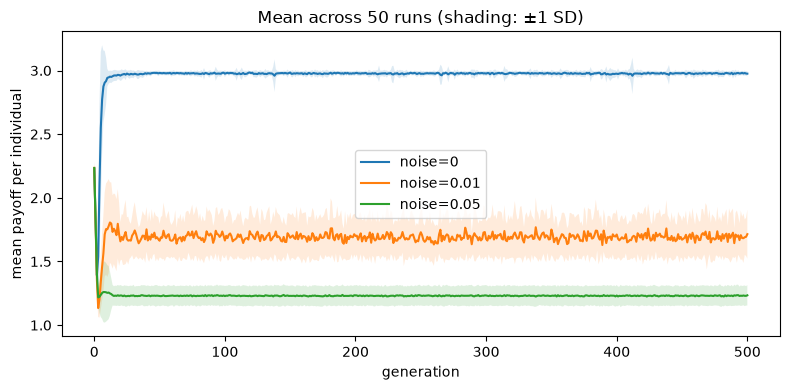

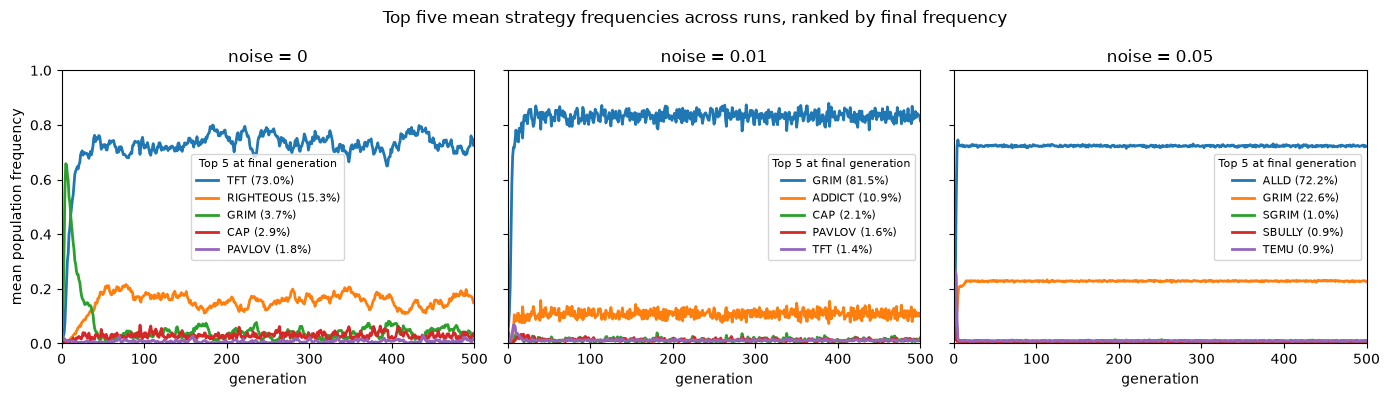

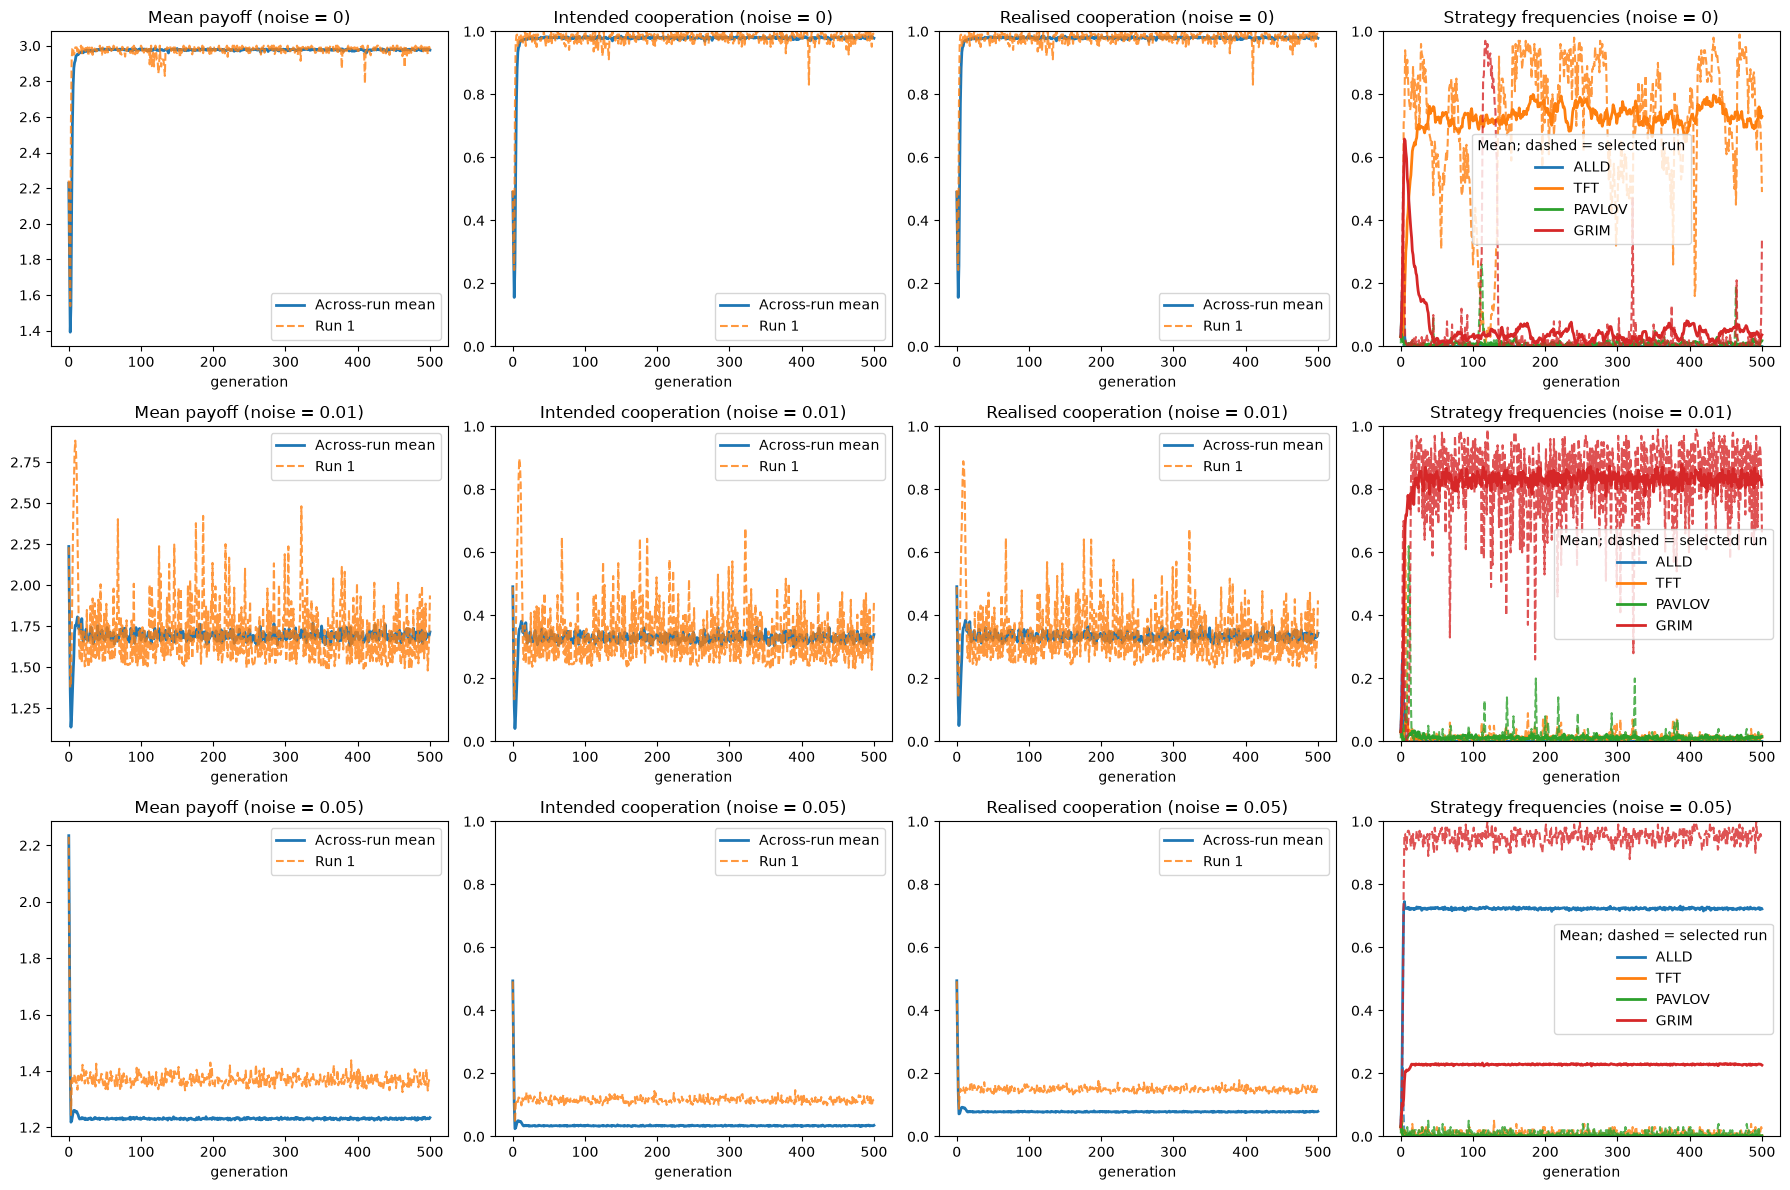

In [98]:
# Plot smoothed mean population payoff across runs; raw values remain in the CSV.
fig, ax = plt.subplots(figsize=(8, 4))
for noise, runs in results.items():
    payoffs = np.array([run["mean_payoff"] for run in runs])
    # kernel = np.ones(ROLLING_WINDOW) / ROLLING_WINDOW
    # smoothed = np.array([np.convolve(row, kernel, mode="valid") for row in payoffs])
    # generations = np.arange(ROLLING_WINDOW - 1, N_GENERATIONS + 1)
    # mean = smoothed.mean(axis=0)
    # sd = smoothed.std(axis=0)
    # ax.plot(generations, mean, label=f"noise={noise}")
    # ax.fill_between(generations, mean - sd, mean + sd, alpha=0.15)
    mean = payoffs.mean(axis=0)
    sd = payoffs.std(axis=0)
    ax.plot(np.arange(N_GENERATIONS + 1), mean, label=f"noise={noise}")
    ax.fill_between(np.arange(N_GENERATIONS + 1), mean - sd, mean + sd, alpha=0.15)
ax.set_xlabel("generation")
ax.set_ylabel("mean payoff per individual")
ax.set_title(f"Mean across {N_RUNS} runs (shading: ±1 SD)")
ax.legend()
fig.tight_layout()
plt.show()

# Plot only the five strategies with the highest across-run mean frequency at the final generation.
fig, axes = plt.subplots(1, len(NOISE_LEVELS), figsize=(14, 4), sharey=True)
strategy_colors = plt.get_cmap("tab10")
for ax, noise in zip(axes, NOISE_LEVELS):
    freq = np.mean([run["freq"] for run in results[noise]], axis=0)
    top_indices = np.argsort(freq[-1])[-5:][::-1]
    for rank, k in enumerate(top_indices):
        strategy = STRATEGIES[k]
        strategy_name = STRATEGY_NAMES.get(strategy, "".join(map(str, strategy)))
        ax.plot(
            freq[:, k],
            color=strategy_colors(rank),
            linewidth=2,
            label=f"{strategy_name} ({freq[-1, k]:.1%})",
        )
    ax.set_title(f"noise = {noise}")
    ax.set_xlabel("generation")
    ax.set_ylim(0, 1)
    ax.set_xlim(0, N_GENERATIONS)
    ax.legend(title="Top 5 at final generation", fontsize=8, title_fontsize=8)
axes[0].set_ylabel("mean population frequency")
fig.suptitle("Top five mean strategy frequencies across runs, ranked by final frequency")
fig.tight_layout()
plt.show()

# Compare the mean with one individual run. Change RUN_TO_INSPECT to inspect
# another zero-based run, or set it to None to show only the means.
RUN_TO_INSPECT = 0
main_strategies = {name: BITS_TO_IDS[strategy] for strategy, name in STRATEGY_NAMES.items()
                   if name in ("TFT", "PAVLOV", "ALLD", "GRIM")}
fig, axes = plt.subplots(len(NOISE_LEVELS), 4, figsize=(18, 4 * len(NOISE_LEVELS)),
                         squeeze=False)
for row, noise in enumerate(NOISE_LEVELS):
    runs = results[noise]
    if RUN_TO_INSPECT is not None and not 0 <= RUN_TO_INSPECT < len(runs):
        raise ValueError(f"RUN_TO_INSPECT must be between 0 and {len(runs) - 1}, or None")
    for col, (key, title) in enumerate([
        ("mean_payoff", "Mean payoff"),
        ("intended_cooperation", "Intended cooperation"),
        ("realized_cooperation", "Realised cooperation"),
    ]):
        ax = axes[row, col]
        trajectories = np.array([run[key] for run in runs])
        ax.plot(trajectories.mean(axis=0), label="Across-run mean", linewidth=2)
        if RUN_TO_INSPECT is not None:
            ax.plot(trajectories[RUN_TO_INSPECT], label=f"Run {RUN_TO_INSPECT + 1}",
                    linestyle="--", alpha=0.8)
        ax.set_title(f"{title} (noise = {noise})")
        ax.set_xlabel("generation")
        if col > 0:
            ax.set_ylim(0, 1)
        ax.legend()

    ax = axes[row, 3]
    for name, strategy_id in main_strategies.items():
        trajectories = np.array([run["freq"][:, strategy_id] for run in runs])
        line, = ax.plot(trajectories.mean(axis=0), label=name, linewidth=2)
        if RUN_TO_INSPECT is not None:
            ax.plot(trajectories[RUN_TO_INSPECT], color=line.get_color(),
                    linestyle="--", alpha=0.8)
    ax.set_title(f"Strategy frequencies (noise = {noise})")
    ax.set_xlabel("generation")
    ax.set_ylim(0, 1)
    ax.legend(title="Mean; dashed = selected run")
fig.tight_layout()
plt.show()

In [38]:
#STAT ANALYSIS
#final cooperation := average over the last 100 generations

import numpy as np
from scipy.stats import wilcoxon

ALPHA = 0.05
FINAL_WINDOW = 100

# Each array contains one observation per independent run.
initial = {}
final = {}
gain = {}

for noise, runs in results.items():
    initial[noise] = np.array([
        run["realized_cooperation"][0] for run in runs
    ])
    final[noise] = np.array([
        run["realized_cooperation"][-FINAL_WINDOW:].mean()
        for run in runs
    ])
    gain[noise] = final[noise] - initial[noise]


In [59]:
#estimate confidence interval of median difference

def bootstrap_ci(differences, n_boot=10000):
    rng = np.random.default_rng(42)
    estimates = []

    for _ in range(n_boot):
        sample = rng.choice(
            differences, size=len(differences), replace=True
        )
        estimates.append(np.median(sample))

    return np.percentile(estimates, [2.5, 97.5])


In [75]:
from statsmodels.stats.multitest import multipletests
# compare initial cooperation to evolved cooperation
# NULL HYPOTHESIS := cooperation differences are symmetric around zero

within_run_p_values = []
for noise in NOISE_LEVELS:
    differences = gain[noise]

    effect = np.median(differences)
    ci = bootstrap_ci(differences)
    p = wilcoxon(differences).pvalue
    within_run_p_values.append(p)

    print(f"\nNoise = {noise}")
    print(f"Median gain: {effect * 100:.2f} pp")
    print(f"95% CI: [{ci[0] * 100:.2f}, {ci[1] * 100:.2f}] pp")
    print(f"Wilcoxon p-value: {p:.20f}")
    print(f"Significant at alpha={ALPHA}: {p < ALPHA}")

reject, p_corr, _, _ = multipletests(within_run_p_values, method="holm")
print(f"Holm corrected p-values: {p_corr}")
print(f"Reject null hypothesis: {reject}")



Noise = 0
Median gain: 48.56 pp
95% CI: [47.89, 49.77] pp
Wilcoxon p-value: 0.00000000000000177636
Significant at alpha=0.05: True

Noise = 0.01
Median gain: -16.00 pp
95% CI: [-16.76, -15.39] pp
Wilcoxon p-value: 0.00000000000000177636
Significant at alpha=0.05: True

Noise = 0.05
Median gain: -42.89 pp
95% CI: [-44.02, -41.90] pp
Wilcoxon p-value: 0.00000000000000177636
Significant at alpha=0.05: True
Holm corrected p-values: [5.32907052e-15 5.32907052e-15 5.32907052e-15]
Reject null hypothesis: [ True  True  True]


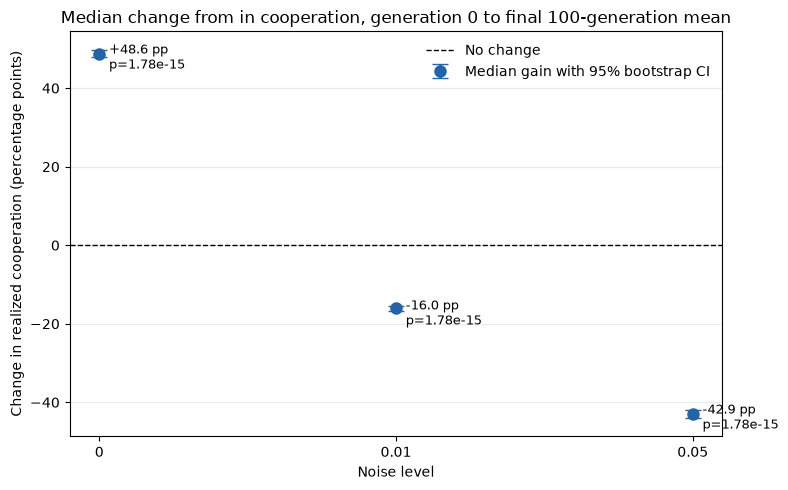

In [67]:
# Median change in realized cooperation, with bootstrap 95% confidence intervals.
noise_levels = list(NOISE_LEVELS)
effects = np.array([np.median(gain[noise]) for noise in noise_levels]) * 100
confidence_intervals = np.array([bootstrap_ci(gain[noise]) for noise in noise_levels]) * 100
p_values = [wilcoxon(gain[noise]).pvalue for noise in noise_levels]

lower_error = effects - confidence_intervals[:, 0]
upper_error = confidence_intervals[:, 1] - effects
x = np.arange(len(noise_levels))
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    x, effects, yerr=np.vstack([lower_error, upper_error]),
    fmt="o", markersize=8, capsize=6, linewidth=2, color="#2563a6",
    label="Median gain with 95% bootstrap CI",
)
ax.axhline(0, color="black", linewidth=1, linestyle="--", label="No change")
for i, (effect, p_value) in enumerate(zip(effects, p_values)):
    ax.annotate(
        f"{effect:+.1f} pp\np={p_value:.3g}",
        (x[i], confidence_intervals[i, 1]), xytext=(7, 5),
        textcoords="offset points", ha="left", va="top", fontsize=9,
    )
ax.set_xticks(x, [f"{noise}" for noise in noise_levels])
ax.set_xlabel("Noise level")
ax.set_ylabel("Change in realized cooperation (percentage points)")
ax.set_title(f"Median change from in cooperation, generation 0 to final {FINAL_WINDOW}-generation mean")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [99]:
from scipy.stats import mannwhitneyu
U_stat1v2, p_stat1v2 = mannwhitneyu(gain[0], gain[0.01], alternative="two-sided")
U_stat2v3, p_stat2v3 = mannwhitneyu(gain[0.01], gain[0.05], alternative="two-sided")
U_stat1v3, p_stat1v3 = mannwhitneyu(gain[0], gain[0.05], alternative="two-sided")

In [100]:
# holm correct three values

p_values = [p_stat1v2, p_stat1v3, p_stat2v3]
reject, p_corr, _, _ = multipletests(p_values, method="holm")
print(f"Holm corrected p-values: {p_corr}")
print(f"Stat1v2: p={stat1v2.pvalue:.3g}, corrected={p_corr[0]:.3g}")
print(f"Stat1v3: p={stat1v3.pvalue:.3g}, corrected={p_corr[1]:.3g}")
print(f"Stat2v3: p={stat2v3.pvalue:.3g}, corrected={p_corr[2]:.3g}")
print(f"Reject null hypothesis: {reject}")

Holm corrected p-values: [2.11982158e-17 2.11982158e-17 2.11982158e-17]
Stat1v2: p=7.07e-18, corrected=2.12e-17
Stat1v3: p=7.07e-18, corrected=2.12e-17
Stat2v3: p=7.07e-18, corrected=2.12e-17
Reject null hypothesis: [ True  True  True]


In [82]:
#Print A12 values
print(f"A12: {U_stat1v2 / (len(gain[0]) * len(gain[0.01]))}")
print(f"A13: {U_stat1v3 / (len(gain[0]) * len(gain[0.05]))}")
print(f"A23: {U_stat2v3 / (len(gain[0.01]) * len(gain[0.05]))}")

A12: 1.0
A13: 1.0
A23: 1.0


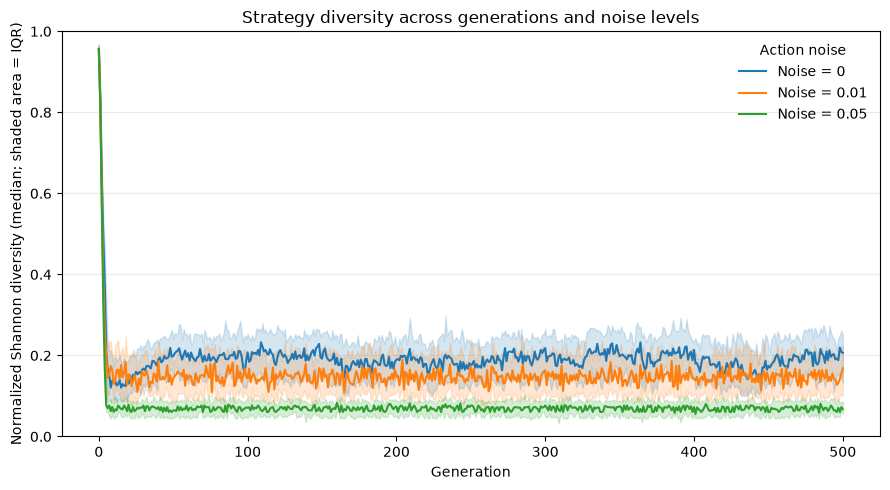

In [92]:
# for each noise level, plot a diversity curve of the population using entropy. Show IQR with each median at each generation
fig, ax = plt.subplots(figsize=(9, 5))
diversity_curves = {}

for noise in NOISE_LEVELS:
    run_entropies = []
    for run in results[noise]:
        frequencies = np.asarray(run["freq"], dtype=float)  # generations x strategies
        log_frequencies = np.log(np.clip(frequencies, np.finfo(float).tiny, 1.0))
        entropy_curve = -np.sum(np.where(frequencies > 0, frequencies * log_frequencies, 0.0), axis=1)
        run_entropies.append(entropy_curve / np.log(len(STRATEGIES)))

    # Summarize variation across independent runs at each generation.
    run_entropies = np.asarray(run_entropies)
    median = np.median(run_entropies, axis=0)
    q1, q3 = np.percentile(run_entropies, [25, 75], axis=0)
    generations = np.arange(len(median))
    line, = ax.plot(generations, median, label=f"Noise = {noise:g}")
    ax.fill_between(generations, q1, q3, color=line.get_color(), alpha=0.18)
    diversity_curves[noise] = {"median": median, "q1": q1, "q3": q3}

ax.set_xlabel("Generation")
ax.set_ylabel("Normalized Shannon diversity (median; shaded area = IQR)")
ax.set_title("Strategy diversity across generations and noise levels")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Action noise", frameon=False)
fig.tight_layout()
plt.show()